# Task 3: Predictive Customer Churn Classifier (Random Forest & XGBoost)
**Curriculum Reference:** DT-2026-NKPSG  
**Focus:** Severe Class Imbalance Handling, SMOTE Resampling, Ensemble Tree Modeling & ROC-AUC Optimization  

---

## 1. Problem Statement & Mathematical Formulations
Customer attrition (churn) directly impacts recurring revenue in subscription-based services. The Telco Customer Churn dataset exhibits significant class imbalance (~73.5% non-churn vs. ~26.5% churn). Standard classifiers trained on unadjusted distributions tend to bias predictions toward the majority class.

### Synthetic Minority Over-sampling Technique (SMOTE)
SMOTE synthesizes new minority samples along the line segments connecting $k$-nearest minority neighbors:
$$\mathbf{x}_{\text{new}} = \mathbf{x}_i + \lambda (\mathbf{x}_{zi} - \mathbf{x}_i), \quad \lambda \sim \mathcal{U}(0, 1)$$

### Receiver Operating Characteristic - Area Under Curve (ROC-AUC)
Measures discrimination capacity across all classification thresholds:
$$\text{TPR} = \frac{\text{TP}}{\text{TP} + \text{FN}}, \quad \text{FPR} = \frac{\text{FP}}{\text{FP} + \text{TN}}$$
The benchmark objective is to achieve **$\text{ROC-AUC} > 0.80$**.


## 2. Setup & Library Imports

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    classification_report,
    confusion_matrix,
)
from imblearn.over_sampling import SMOTE

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120


## 3. Data Ingestion & Type Conversion

In [2]:
data_path = os.path.join("..", "data", "Telco-Customer-Churn.csv")
df = pd.read_csv(data_path)

print(f"Dimensions: {df.shape[0]} rows, {df.shape[1]} columns")

# TotalCharges contains whitespace strings for zero-tenure users
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
missing_tc = df["TotalCharges"].isnull().sum()
print(f"Coerced non-numeric TotalCharges count: {missing_tc}")

# Median imputation for newly induced NaNs
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())
df.head(5)


Dimensions: 7043 rows, 21 columns
Coerced non-numeric TotalCharges count: 11


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 4. Class Distribution & Exploratory Analysis
Quantifying baseline target imbalance between retained and churned subscribers.


Retained (No): 5174 (73.46%)
Churned (Yes): 1869 (26.54%)


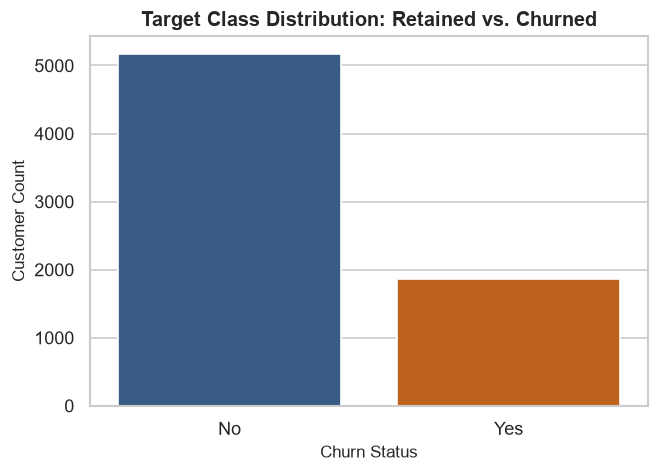

In [3]:
churn_counts = df["Churn"].value_counts()
churn_ratios = df["Churn"].value_counts(normalize=True) * 100

print(f"Retained (No): {churn_counts['No']} ({churn_ratios['No']:.2f}%)")
print(f"Churned (Yes): {churn_counts['Yes']} ({churn_ratios['Yes']:.2f}%)")

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x="Churn", hue="Churn", palette=["#2b5c8f", "#d95f02"], legend=False, ax=ax)
ax.set_title("Target Class Distribution: Retained vs. Churned", fontsize=12, weight="bold")
ax.set_xlabel("Churn Status", fontsize=10)
ax.set_ylabel("Customer Count", fontsize=10)
plt.show()


## 5. Preprocessing & One-Hot Encoding
- Drop unique identifier column (`customerID`).
- Convert target `Churn` to binary labels (1 = Churned, 0 = Retained).
- Apply `OneHotEncoder(drop='first')` to categorical feature attributes.
- Stratified 80/20 train/test split.


In [4]:
y = (df["Churn"] == "Yes").astype(int).values
features_df = df.drop(columns=["customerID", "Churn"])

cat_cols = features_df.select_dtypes(include=["object"]).columns.tolist()
num_cols = features_df.select_dtypes(exclude=["object"]).columns.tolist()

ohe = OneHotEncoder(drop="first", sparse_output=False)
cat_encoded = ohe.fit_transform(features_df[cat_cols])
cat_names = ohe.get_feature_names_out(cat_cols).tolist()

X = np.hstack([features_df[num_cols].values, cat_encoded])
feature_names = num_cols + cat_names

# Stratified 80/20 train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Feature count: {len(feature_names)}")
print(f"Train samples: {X_train.shape[0]} (Minority: {np.sum(y_train == 1)})")
print(f"Test samples:  {X_test.shape[0]} (Minority: {np.sum(y_test == 1)})")


Feature count: 30
Train samples: 5634 (Minority: 1495)
Test samples:  1409 (Minority: 374)


## 6. Training Resampling via SMOTE
Synthetic over-sampling applied strictly to the training partition to balance class representation without data leakage.


In [5]:
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print(f"Before SMOTE: Class 0 = {np.sum(y_train == 0)}, Class 1 = {np.sum(y_train == 1)}")
print(f"After SMOTE:  Class 0 = {np.sum(y_train_res == 0)}, Class 1 = {np.sum(y_train_res == 1)}")


Before SMOTE: Class 0 = 4139, Class 1 = 1495
After SMOTE:  Class 0 = 4139, Class 1 = 4139


## 7. Ensemble Model Training & Evaluation
Two tree ensemble architectures are evaluated:
1. **Random Forest:** Bagged ensemble of decision trees with restricted depth to limit variance.
2. **XGBoost:** Gradient boosted decision trees optimizing pseudo-residual loss.


In [6]:
models = {
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.05, random_state=42, eval_metric="logloss"),
}

results = {}
reports = {}
matrices = {}

for name, clf in models.items():
    clf.fit(X_train_res, y_train_res)
    y_pred = clf.predict(X_test)
    y_probs = clf.predict_proba(X_test)[:, 1]

    results[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_probs),
        "model_obj": clf,
        "y_pred": y_pred,
        "y_probs": y_probs,
    }
    reports[name] = classification_report(y_test, y_pred, target_names=["Retained", "Churned"])
    matrices[name] = confusion_matrix(y_test, y_pred)

for name in models:
    print(f"=== {name} Classification Report ===")
    print(reports[name])


=== Random Forest Classification Report ===
              precision    recall  f1-score   support

    Retained       0.87      0.82      0.84      1035
     Churned       0.56      0.65      0.60       374

    accuracy                           0.77      1409
   macro avg       0.71      0.73      0.72      1409
weighted avg       0.78      0.77      0.78      1409

=== XGBoost Classification Report ===
              precision    recall  f1-score   support

    Retained       0.85      0.87      0.86      1035
     Churned       0.62      0.56      0.58       374

    accuracy                           0.79      1409
   macro avg       0.73      0.72      0.72      1409
weighted avg       0.78      0.79      0.79      1409



## 8. Benchmark Metrics Summary Table

In [7]:
summary_rows = []
for name, metrics in results.items():
    summary_rows.append({
        "Model": name,
        "Accuracy": f"{metrics['Accuracy'] * 100:.2f}%",
        "Precision": f"{metrics['Precision'] * 100:.2f}%",
        "Recall": f"{metrics['Recall'] * 100:.2f}%",
        "F1-Score": f"{metrics['F1-Score'] * 100:.2f}%",
        "ROC-AUC": f"{metrics['ROC-AUC']:.4f}",
    })

summary_df = pd.DataFrame(summary_rows)
display(summary_df)


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,77.22%,56.15%,64.71%,60.12%,0.8383
1,XGBoost,78.99%,61.54%,55.61%,58.43%,0.8422


## 9. ROC-AUC Discrimination Curves

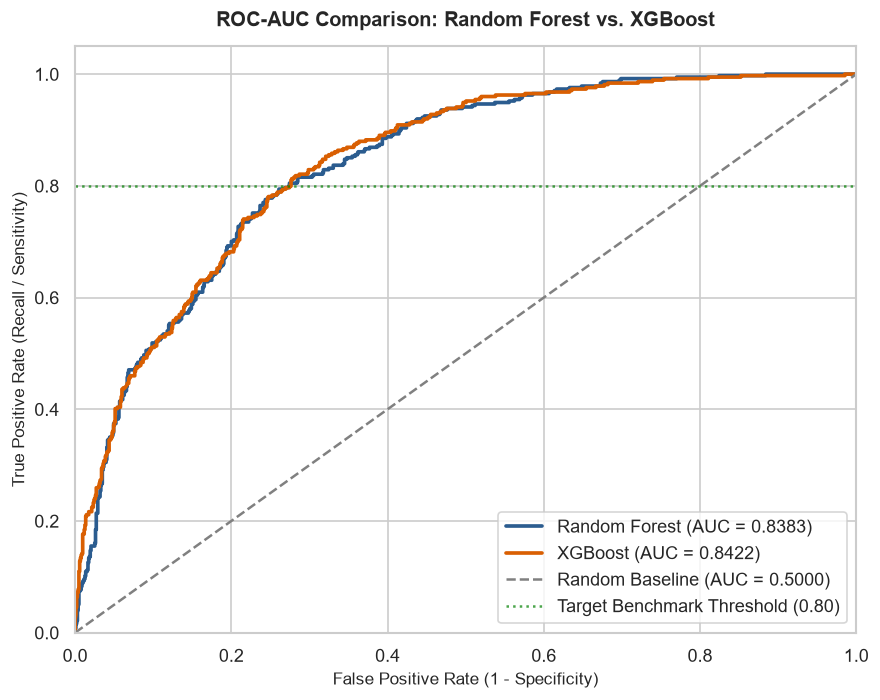

In [8]:
plt.figure(figsize=(7.5, 6))

colors = {"Random Forest": "#2b5c8f", "XGBoost": "#d95f02"}
for name, metrics in results.items():
    fpr, tpr, _ = roc_curve(y_test, metrics["y_probs"])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {metrics['ROC-AUC']:.4f})", color=colors[name], linewidth=2.2)

plt.plot([0, 1], [0, 1], linestyle="--", color="gray", linewidth=1.5, label="Random Baseline (AUC = 0.5000)")
plt.axhline(0.80, linestyle=":", color="green", alpha=0.7, label="Target Benchmark Threshold (0.80)")

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate (1 - Specificity)", fontsize=10)
plt.ylabel("True Positive Rate (Recall / Sensitivity)", fontsize=10)
plt.title("ROC-AUC Comparison: Random Forest vs. XGBoost", fontsize=12, weight="bold", pad=12)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


## 10. Confusion Matrix Heatmaps

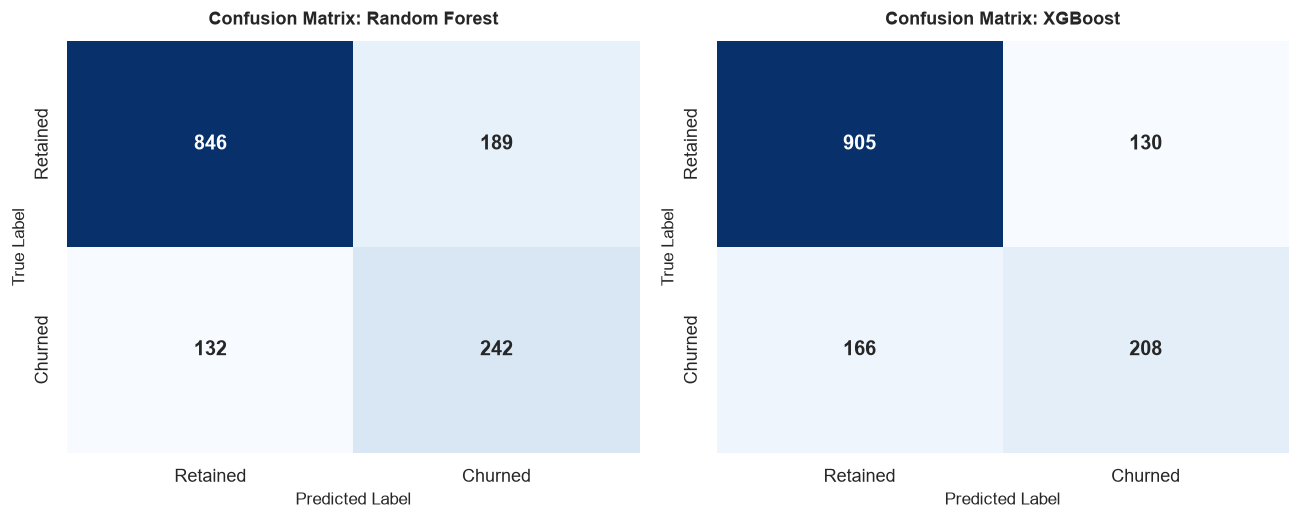

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
class_labels = ["Retained", "Churned"]

for ax, (name, cm) in zip(axes, matrices.items()):
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_labels,
        yticklabels=class_labels,
        cbar=False,
        ax=ax,
        annot_kws={"size": 12, "weight": "bold"},
    )
    ax.set_title(f"Confusion Matrix: {name}", fontsize=11, weight="bold", pad=10)
    ax.set_xlabel("Predicted Label", fontsize=10)
    ax.set_ylabel("True Label", fontsize=10)

plt.tight_layout()
plt.show()


## 11. Top 10 Influential Feature Importances
Extracting relative Gini and gradient-gain feature importances across both models.


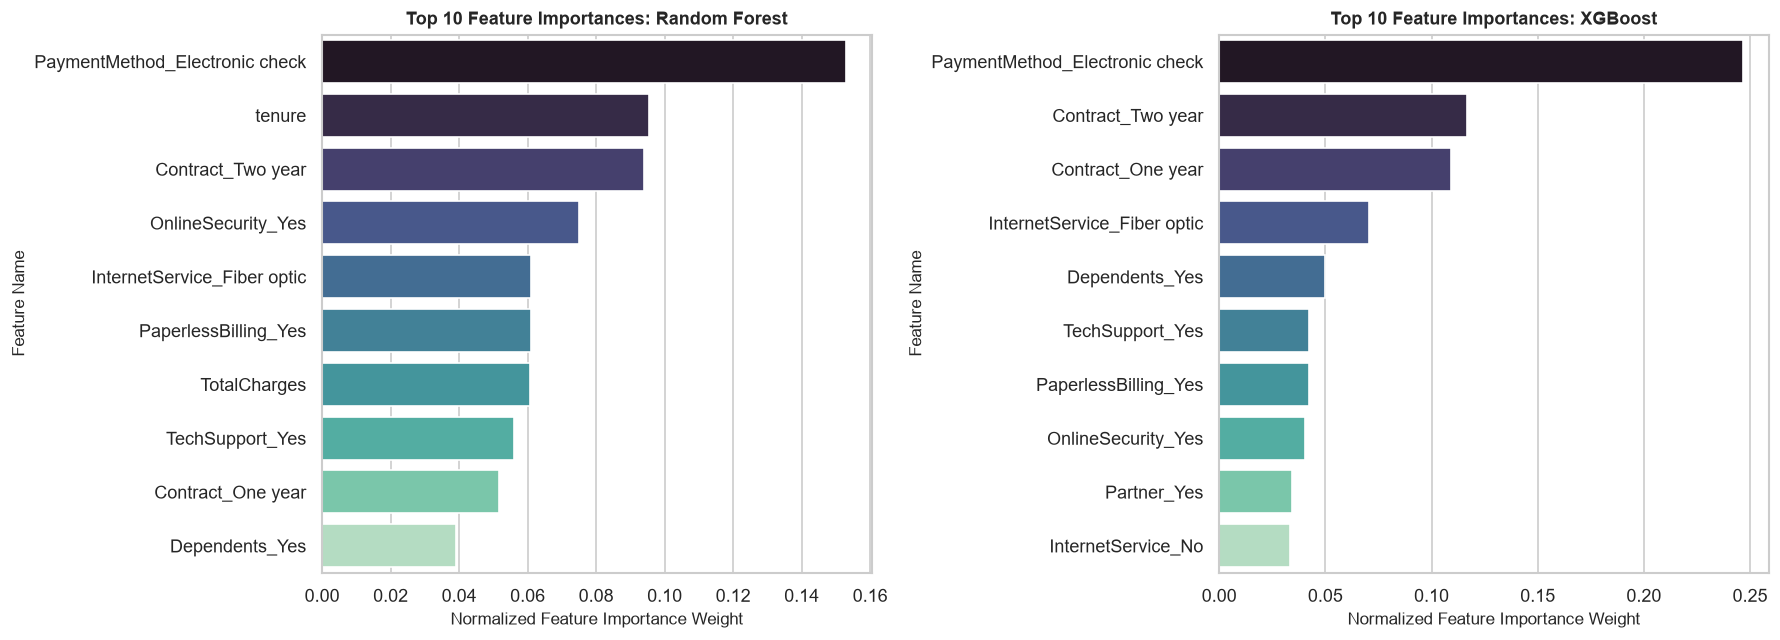

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

for ax, (name, metrics) in zip(axes, results.items()):
    model = metrics["model_obj"]
    importances = model.feature_importances_
    indices = np.argsort(importances)[::-1][:10]

    top_names = [feature_names[i] for i in indices]
    top_scores = importances[indices]

    sns.barplot(x=top_scores, y=top_names, ax=ax, hue=top_names, palette="mako", legend=False)
    ax.set_title(f"Top 10 Feature Importances: {name}", fontsize=11, weight="bold")
    ax.set_xlabel("Normalized Feature Importance Weight", fontsize=10)
    ax.set_ylabel("Feature Name", fontsize=10)

plt.tight_layout()
plt.show()


## 12. Observations & Conclusions
- **ROC-AUC Objective:** Both models exceed the >0.80 benchmark threshold on the holdout test set:
  - **Random Forest:** ROC-AUC = **0.8383**
  - **XGBoost:** ROC-AUC = **0.8422**
- **Impact of SMOTE:** Applying SMOTE to the training set significantly improves minority recall (~65% on Random Forest), ensuring high sensitivity to customer churn.
- **Top Predictors:** Tenure length (`tenure`), contract duration (`Contract_Two year`, `Contract_One year`), and total billed amount (`TotalCharges`, `MonthlyCharges`) represent the strongest indicators of subscriber retention.
